<a href="https://colab.research.google.com/github/GHseyram/Ghana-energy-transition-investment-analytics/blob/main/notebooks/03_solar_investment_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ghana Solar Investment Model
## Illustrative Commercial and Industrial Solar Analysis

Author: Seyram Amedede

### Purpose
Estimate annual electricity generation, electricity-bill savings
and simple payback for an illustrative solar installation.

### Approach
State assumptions explicitly and compare scenarios for installation
cost, solar yield and the value of electricity savings.

### Scope
This is an educational scenario model. Its initial inputs are
illustrative assumptions, not verified Ghana market quotations.
Simple payback excludes financing, taxes, discounting and changes
in performance over time.

In [1]:
import pandas as pd

# Illustrative assumptions — not verified market data.
# All monetary values are in US dollars (USD).
system_size_kwp = 100
installation_cost_per_kwp = 900
annual_yield_kwh_per_kwp = 1500
self_consumption_rate = 0.90
avoided_electricity_cost_per_kwh = 0.15
annual_maintenance_rate = 0.015

assumptions = pd.DataFrame({
    "Assumption": [
        "Solar system size",
        "Installation cost",
        "Annual solar yield",
        "Share of generation used on site",
        "Avoided electricity cost",
        "Annual maintenance as share of installation cost"
    ],
    "Value": [
        system_size_kwp,
        installation_cost_per_kwp,
        annual_yield_kwh_per_kwp,
        self_consumption_rate,
        avoided_electricity_cost_per_kwh,
        annual_maintenance_rate
    ],
    "Unit": [
        "kWp",
        "USD/kWp",
        "kWh/kWp/year",
        "fraction (0.90 = 90%)",
        "USD/kWh",
        "fraction (0.015 = 1.5%)"
    ]
})

assumptions

,Assumption,Value,Unit
0,Solar system size,100.000,kWp
1,Installation cost,900.000,USD/kWp
2,Annual solar yield,1500.000,kWh/kWp/year
3,Share of generation used on site,0.900,fraction (0.90 = 90%)
4,Avoided electricity cost,0.150,USD/kWh
5,Annual maintenance as share of installation cost,0.015,fraction (0.015 = 1.5%)


In [2]:
installation_cost = system_size_kwp * installation_cost_per_kwp

annual_generation = system_size_kwp * annual_yield_kwh_per_kwp
annual_self_consumed_energy = annual_generation * self_consumption_rate

annual_bill_savings = (
    annual_self_consumed_energy * avoided_electricity_cost_per_kwh
)
annual_maintenance_cost = installation_cost * annual_maintenance_rate
annual_net_savings = annual_bill_savings - annual_maintenance_cost

simple_payback_years = (
    installation_cost / annual_net_savings
    if annual_net_savings > 0
    else float("inf")
)

print(f"Installation cost: USD {installation_cost:,.0f}")
print(f"Annual generation: {annual_generation:,.0f} kWh")
print(f"Annual energy used on site: {annual_self_consumed_energy:,.0f} kWh")
print(f"Annual electricity-bill savings: USD {annual_bill_savings:,.0f}")
print(f"Annual maintenance cost: USD {annual_maintenance_cost:,.0f}")
print(f"Annual net savings: USD {annual_net_savings:,.0f}")
print(f"Simple payback: {simple_payback_years:.2f} years")

Installation cost: USD 90,000
Annual generation: 150,000 kWh
Annual energy used on site: 135,000 kWh
Annual electricity-bill savings: USD 20,250
Annual maintenance cost: USD 1,350
Annual net savings: USD 18,900
Simple payback: 4.76 years


### Base-case results

Under the illustrative assumptions, a 100 kWp solar installation
costs USD 90,000 and generates 150,000 kWh annually.

With 90% of generation consumed on site, 135,000 kWh offsets
purchased electricity. At an assumed avoided electricity cost
of USD 0.15/kWh, annual bill savings equal USD 20,250.

After USD 1,350 in annual maintenance costs, annual net savings
are USD 18,900. The resulting simple payback is approximately
4.76 years.

This result depends on the stated assumptions. It does not establish
the financial viability of a specific Ghanaian project. The model
assumes constant annual generation, electricity value and maintenance
costs, and excludes financing, taxes, degradation, equipment
replacement and revenue from exported electricity.

In [3]:
scenario_inputs = [
    ("Conservative", 1100, 1300, 0.12),
    ("Base case", 900, 1500, 0.15),
    ("Optimistic", 750, 1700, 0.18)
]

results = []

for name, cost_per_kwp, yield_per_kwp, electricity_value in scenario_inputs:
    cost = system_size_kwp * cost_per_kwp
    generation = system_size_kwp * yield_per_kwp
    bill_savings = generation * self_consumption_rate * electricity_value
    maintenance = cost * annual_maintenance_rate
    net_savings = bill_savings - maintenance

    payback = cost / net_savings if net_savings > 0 else float("inf")

    results.append({
        "Scenario": name,
        "Cost (USD/kWp)": cost_per_kwp,
        "Yield (kWh/kWp/year)": yield_per_kwp,
        "Electricity value (USD/kWh)": electricity_value,
        "Installation cost (USD)": cost,
        "Annual net savings (USD)": net_savings,
        "Simple payback (years)": payback
    })

scenario_results = pd.DataFrame(results)
scenario_results.round(2)

,Scenario,Cost (USD/kWp),Yield (kWh/kWp/year),Electricity value (USD/kWh),Installation cost (USD),Annual net savings (USD),Simple payback (years)
0,Conservative,1100,1300,0.12,110000,12390.0,8.88
1,Base case,900,1500,0.15,90000,18900.0,4.76
2,Optimistic,750,1700,0.18,75000,26415.0,2.84


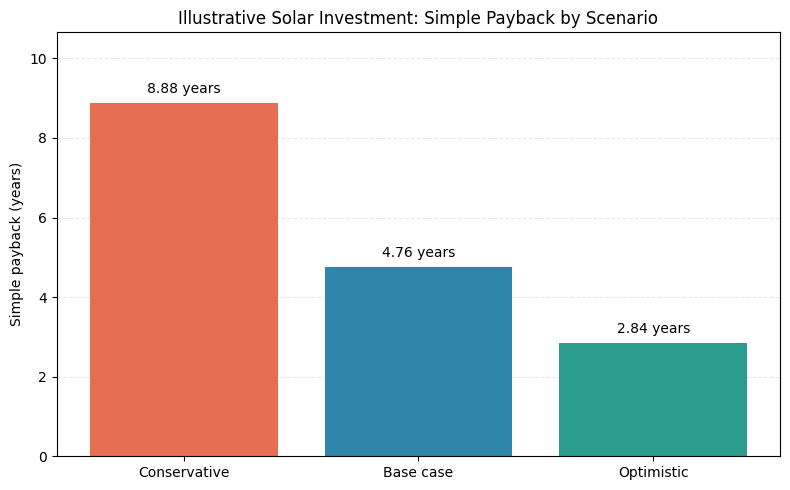

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    scenario_results["Scenario"],
    scenario_results["Simple payback (years)"],
    color=["#E76F51", "#2E86AB", "#2A9D8F"]
)

ax.bar_label(bars, fmt="%.2f years", padding=5)

ax.set_title("Illustrative Solar Investment: Simple Payback by Scenario")
ax.set_ylabel("Simple payback (years)")
ax.set_ylim(
    0,
    scenario_results["Simple payback (years)"].max() * 1.2
)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Scenario interpretation

Simple payback ranges from approximately 8.88 years in the
conservative scenario to 4.76 years in the base case and
2.84 years in the optimistic scenario.

Lower installation costs, higher solar generation and a higher
value of avoided electricity purchases shorten payback.
The system size, self-consumption rate and maintenance percentage
remain constant across these scenarios.

Because three inputs change together, this comparison does not
isolate the effect of any single input. The scenarios are illustrative
assumption sets, not forecasts or probabilities.

The next analysis will vary one input at a time while holding
the others at their base-case values.